# Supplementary Figure 2 — PQC complex slopes vs TMB (per cancer type)

Forest-style panels: OLS slope of each PQC complex score vs log TMB (+ purity), one panel per complex.
Cancer types ordered like fig2a (TMB axis r, high → low).

Output: `results/figures/supplementary/supp_fig2/pqc_complex_slope.pdf`

In [6]:
import os
import socket
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from matplotlib.gridspec import GridSpec

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

OUT_DIR = f"{BASE_DIR}/results/figures/supplementary/supp_fig2"
os.makedirs(OUT_DIR, exist_ok=True)

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS


def rasterize_figure(fig):
    """Rasterize line/marker artists in PDF; text stays vector."""
    from matplotlib.collections import LineCollection, PathCollection, PolyCollection
    from matplotlib.lines import Line2D

    for ax in fig.axes:
        for artist in ax.get_children():
            if isinstance(artist, (Line2D, PathCollection, LineCollection, PolyCollection)):
                artist.set_rasterized(True)

In [7]:
complex_scores_df = pd.read_csv(f"{BASE_DIR}/analysis/03_complex/complex_axis_score.csv")

id_cols = ["barcode", "cancer_type", "log_mut", "purity"]
value_cols = [c for c in complex_scores_df.columns if c not in id_cols + ["tmb_bin"]]

df_long = complex_scores_df[id_cols + value_cols].melt(
    id_vars=id_cols,
    var_name="complex",
    value_name="score",
)

In [8]:
results = []

for (cancer_type, complex), df_ct in df_long.groupby(["cancer_type", "complex"]):
    X = sm.add_constant(df_ct[["log_mut", "purity"]])
    y = df_ct["score"]
    model = sm.OLS(y, X).fit()

    results.append({
        "cancer_type": cancer_type,
        "complex": complex,
        "slope": model.params["log_mut"],
        "slope_ci_low": model.conf_int().loc["log_mut", 0],
        "slope_ci_high": model.conf_int().loc["log_mut", 1],
        "n": len(df_ct),
    })

df_slopes = pd.DataFrame(results)

In [9]:
# Optional: save slope table
df_slopes.to_csv(f"{BASE_DIR}/results/tables/tableS2/pqc_slope.csv", index=False)


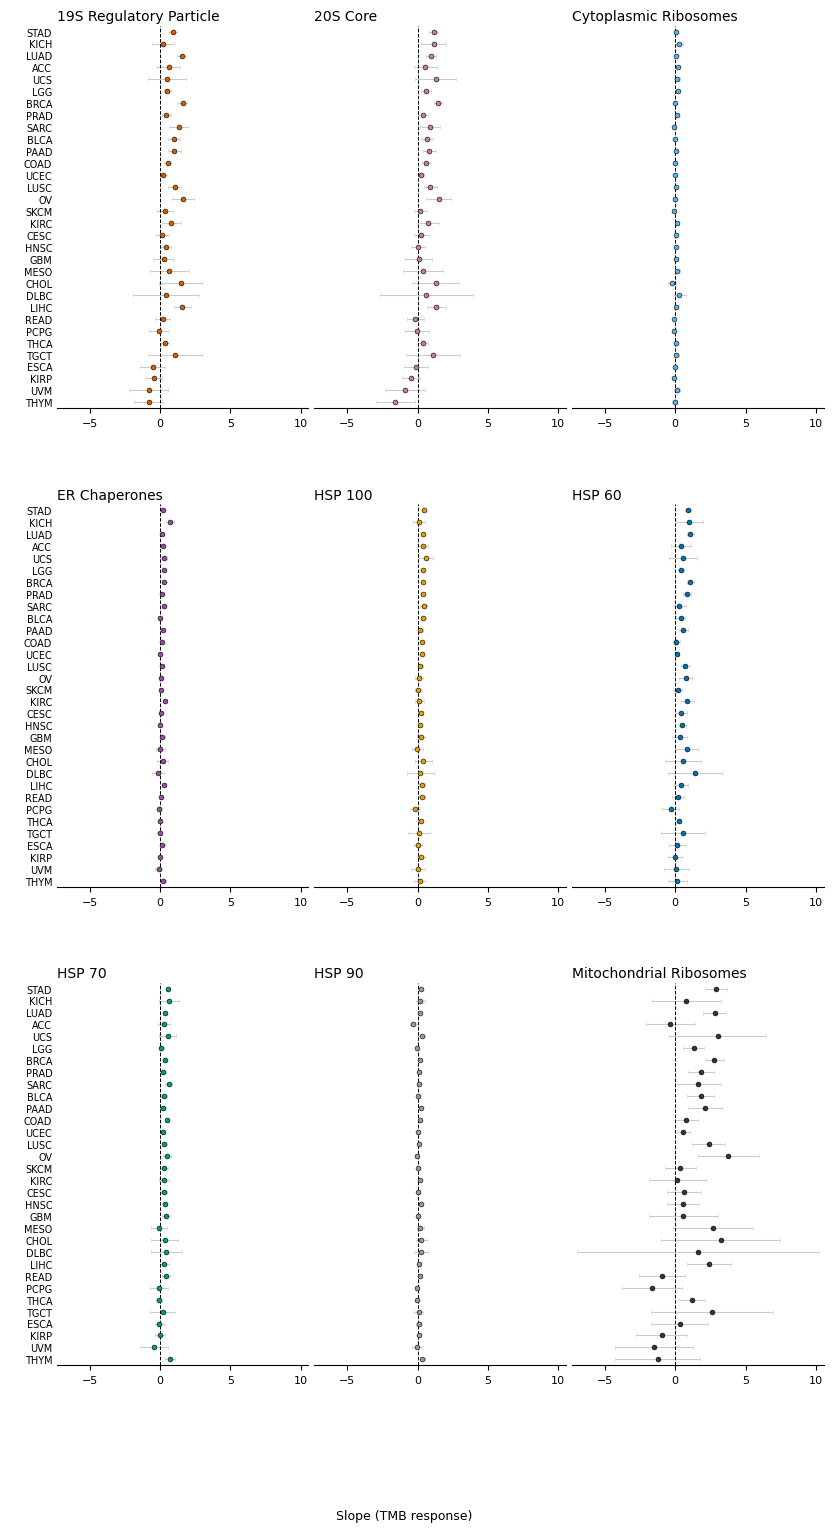

In [10]:
CANCER_ORDER = (
    pd.read_csv(f"{BASE_DIR}/results/tables/score_corr_per_type_summary.csv")
    .loc[lambda d: d["score"] == "TMB_axis_score"]
    .sort_values("r", ascending=False)["cancer_type"]
    .tolist()
)

CI_COLOR = COLORS["light_gray"]

palette_cycle = [
    COLORS["high"],
    COLORS["accent2"],
    COLORS["accent3"],
    COLORS["accent5"],
    COLORS["accent4"],
    COLORS["low"],
    COLORS["accent1"],
    COLORS["ns"],
    COLORS["dark_gray"],
]
COMPLEXES = sorted(df_slopes["complex"].unique())
COMPLEX_PALETTE = dict(zip(COMPLEXES, palette_cycle[: len(COMPLEXES)]))

N_COLS = 3
N_ROWS = int(np.ceil(len(COMPLEXES) / N_COLS))
PANEL_SIZE = 3.2  # square data-panel side (inches)
LABEL_WIDTH = 0.85  # narrow column for cancer-type labels
FIG_WIDTH = LABEL_WIDTH + N_COLS * PANEL_SIZE
FIG_HEIGHT = N_ROWS * PANEL_SIZE


def _style_label_axis(ax_y, order, y):
    ax_y.set_yticks(y)
    ax_y.set_yticklabels(order, fontsize=7, ha="right")
    ax_y.set_ylim(-0.5, len(order) - 0.5)
    ax_y.invert_yaxis()
    ax_y.set_xticks([])
    ax_y.set_xlim(0, 1)
    ax_y.tick_params(axis="x", bottom=False)
    ax_y.tick_params(axis="y", length=0, pad=1, labelleft=False, labelright=True)
    ax_y.yaxis.set_ticks_position("right")
    for spine in ax_y.spines.values():
        spine.set_visible(False)


def plot_slope_by_complex_panels(df, filename):
    """Forest-style panels: all cancer types together within each complex."""
    order = CANCER_ORDER
    y = np.arange(len(order))

    x_min = df["slope_ci_low"].min()
    x_max = df["slope_ci_high"].max()
    pad = 0.02 * (x_max - x_min)

    fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))
    gs = GridSpec(
        N_ROWS,
        N_COLS + 1,
        figure=fig,
        width_ratios=[LABEL_WIDTH / PANEL_SIZE] + [1.0] * N_COLS,
        height_ratios=[1.0] * N_ROWS,
        wspace=0.04,
        hspace=0.06,
    )
    row_label_axes = {}

    for i, complex_name in enumerate(COMPLEXES):
        row, col = divmod(i, N_COLS)
        if row not in row_label_axes:
            ax_y = fig.add_subplot(gs[row, 0])
            _style_label_axis(ax_y, order, y)
            row_label_axes[row] = ax_y

        ax = fig.add_subplot(gs[row, col + 1], sharey=row_label_axes[row])
        ax.set_box_aspect(1)
        df_sub = (
            df[df["complex"] == complex_name]
            .set_index("cancer_type")
            .reindex(order)
        )

        ax.errorbar(
            df_sub["slope"],
            y,
            xerr=[
                df_sub["slope"] - df_sub["slope_ci_low"],
                df_sub["slope_ci_high"] - df_sub["slope"],
            ],
            fmt="o",
            color=COMPLEX_PALETTE[complex_name],
            ecolor=CI_COLOR,
            elinewidth=0.8,
            capsize=1.5,
            markersize=3.5,
            markeredgecolor="black",
            markeredgewidth=0.4,
        )
        ax.axvline(0, color="black", linewidth=0.7, linestyle="--")
        ax.set_title(complex_name, fontsize=9, loc="left", pad=2)
        ax.set_xlim(x_min - pad, x_max + pad)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.tick_params(axis="x", labelsize=8)
        sns.despine(ax=ax, left=True, bottom=False)

    fig.supxlabel("Slope (TMB response)", fontsize=9, y=0.01)
    fig.subplots_adjust(left=0.06, right=0.99, top=0.97, bottom=0.05)
    rasterize_figure(fig)
    plt.savefig(f"{OUT_DIR}/{filename}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.08)
    plt.show()


plot_slope_by_complex_panels(df_slopes, "pqc_complex_slope")